# Анализ данных для обоснования актуальности бота для отслеживания привычек

**Тема работы:** Бот для отслеживания привычек (формирование полезных привычек и отказ от вредных).  
**Цель анализа:** На основе статистических данных и результатов опроса показать актуальность разработки бота, определить основные сложности людей при формировании привычек и обосновать выбор функциональных модулей (ежедневные отметки, серии, статистика и отчёты).

### Используемые наборы данных:
1. **`obesity_by_region.csv`** — динамика доли взрослого населения с ожирением по регионам мира (1975–2014 гг.).
2. **`smoking_by_country.csv`** — статистика распространённости курения и среднего числа сигарет в день по странам (1980–2012 гг.).
3. **`alcohol_drug_disorders_by_country.csv`** — распространённость алкогольных/наркотических расстройств, смертность и ментальные расстройства по странам (1990–2016 гг.).
4. **`desired_habits_survey.csv`** — опрос 1 000 человек о желаемых привычках, главных препятствиях и сроке удержания привычки.

## 1. Импорт библиотек и первичный обзор данных

Для работы используются библиотеки `pandas`, `numpy` и `matplotlib`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

obesity = pd.read_csv('obesity_by_region.csv')
smoking = pd.read_csv('smoking_by_country.csv')
alcohol = pd.read_csv('alcohol_drug_disorders_by_country.csv')
survey = pd.read_csv('desired_habits_survey.csv')

print("obesity:", obesity.shape, "пропусков:", obesity.isna().sum().sum())
print("smoking:", smoking.shape, "пропусков:", smoking.isna().sum().sum())
print("alcohol:", alcohol.shape, "пропусков:", alcohol.isna().sum().sum())
print("survey:", survey.shape, "пропусков:", survey.isna().sum().sum())

display(survey.head(3))

obesity: (240, 3) пропусков: 0
smoking: (6204, 6) пропусков: 217
alcohol: (5292, 7) пропусков: 0
survey: (1000, 7) пропусков: 0


,respondent_id,gender,age_group,desired_habit,main_obstacle,days_kept,still_keeping
0,1,Ж,45+,Здоровый сон,Слишком строгие правила для себя,88,1
1,2,М,18-24,Медитация и ментальное здоровье,Нереалистичные ожидания,196,0
2,3,Ж,35-44,Питьевой режим (вода),Старые привычки,64,1


## 2. Динамика ожирения по регионам (актуальность полезных привычек)

Недостаток физической активности, нарушение питьевого режима и несбалансированное питание напрямую влияют на рост числа людей с лишним весом. Рассмотрим динамику показателя по регионам мира за 1975–2014 гг.

year,1975,2014,Прирост (п.п.)
region,,,
North America and Europe,11.1,27.7,16.6
Oceania,9.6,27.5,17.9
Latin America and the Caribbean,6.8,22.8,16.0
World,4.5,12.8,8.3
Africa,3.0,11.1,8.1
Asia,1.0,7.4,6.4


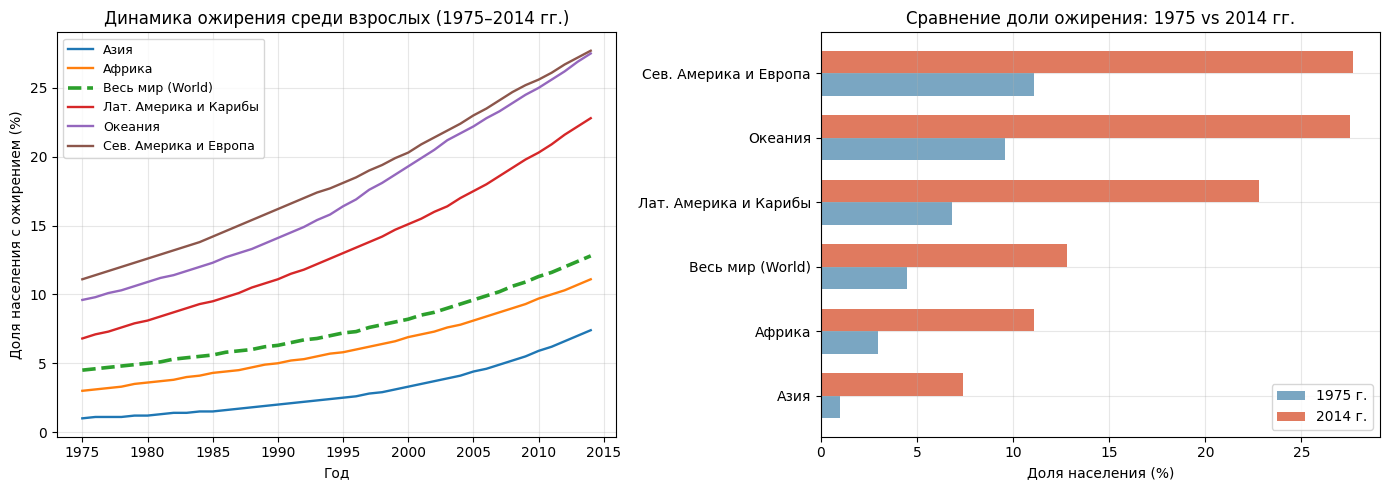

In [2]:
min_y = obesity['year'].min()
max_y = obesity['year'].max()

obesity_tab = obesity[obesity['year'].isin([min_y, max_y])].pivot(
    index='region', columns='year', values='obesity_pct_adults'
)
obesity_tab['Прирост (п.п.)'] = (obesity_tab[max_y] - obesity_tab[min_y]).round(1)
display(obesity_tab.sort_values(by=max_y, ascending=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

names = {
    'North America and Europe': 'Сев. Америка и Европа',
    'Oceania': 'Океания',
    'Latin America and the Caribbean': 'Лат. Америка и Карибы',
    'World': 'Весь мир (World)',
    'Africa': 'Африка',
    'Asia': 'Азия'
}
obesity['region_ru'] = obesity['region'].map(names)

# тренды по годам
for reg, grp in obesity.groupby('region_ru'):
    if 'World' in reg:
        ax1.plot(grp['year'], grp['obesity_pct_adults'], label=reg, linewidth=2.6, linestyle='--')
    else:
        ax1.plot(grp['year'], grp['obesity_pct_adults'], label=reg, linewidth=1.7)

ax1.set_title('Динамика ожирения среди взрослых (1975–2014 гг.)')
ax1.set_xlabel('Год')
ax1.set_ylabel('Доля населения с ожирением (%)')
ax1.legend(fontsize=9)

# сравнение начала и конца периода
comp = obesity[obesity['year'].isin([min_y, max_y])].pivot(
    index='region_ru', columns='year', values='obesity_pct_adults'
).sort_values(by=max_y)

y = np.arange(len(comp))
h = 0.35

ax2.barh(y - h/2, comp[min_y], h, label=f'{min_y} г.', color='#7aa6c2')
ax2.barh(y + h/2, comp[max_y], h, label=f'{max_y} г.', color='#e07a5f')
ax2.set_yticks(y)
ax2.set_yticklabels(comp.index)
ax2.set_title(f'Сравнение доли ожирения: {min_y} vs {max_y} гг.')
ax2.set_xlabel('Доля населения (%)')
ax2.legend()

plt.tight_layout()
plt.show()

## 3. Статистика курения (актуальность отказа от вредных привычек)

Вторая важная задача бота — помощь в отказе от вредных привычек с помощью ежедневной вечерней отметки («Да / Нет») и подсчёта серий дней без срывов. Проанализируем уровень курения и количество выкуриваемых сигарет в день.

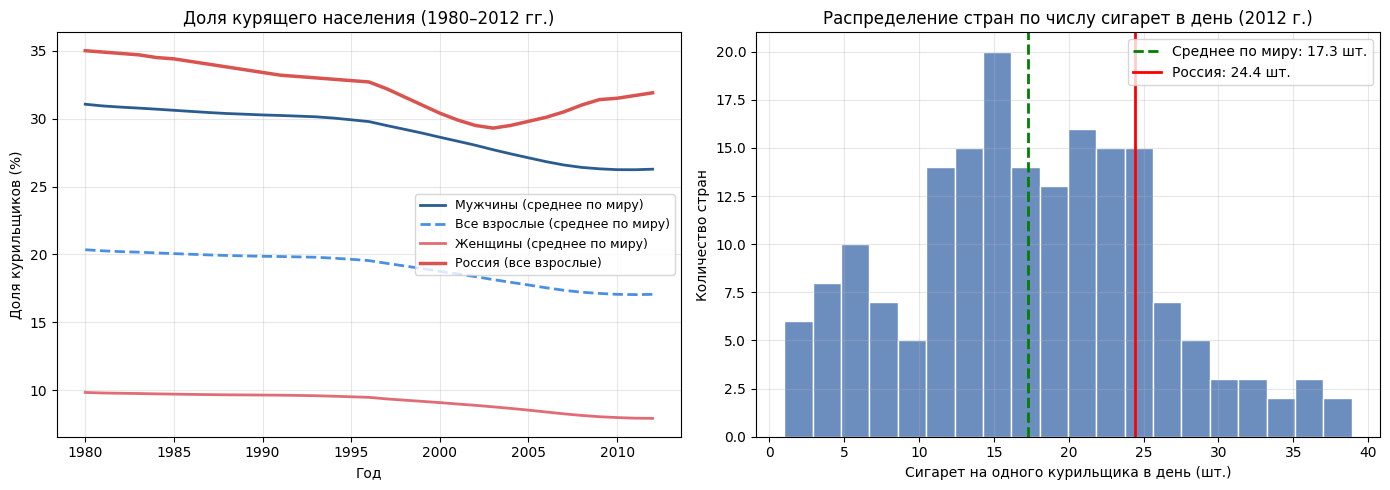

In [3]:
smoke_world = smoking.groupby('year')[['smokers_pct_all', 'smokers_pct_male', 'smokers_pct_female']].mean().reset_index()
smoke_rus = smoking[smoking['country'] == 'Russia'].sort_values('year')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(smoke_world['year'], smoke_world['smokers_pct_male'], label='Мужчины (среднее по миру)', color='#2b5c8f', linewidth=2)
ax1.plot(smoke_world['year'], smoke_world['smokers_pct_all'], label='Все взрослые (среднее по миру)', color='#4a90e2', linestyle='--', linewidth=2)
ax1.plot(smoke_world['year'], smoke_world['smokers_pct_female'], label='Женщины (среднее по миру)', color='#e06c75', linewidth=2)
ax1.plot(smoke_rus['year'], smoke_rus['smokers_pct_all'], label='Россия (все взрослые)', color='#d9534f', linewidth=2.5)

ax1.set_title('Доля курящего населения (1980–2012 гг.)')
ax1.set_xlabel('Год')
ax1.set_ylabel('Доля курильщиков (%)')
ax1.legend(fontsize=9)

last_y = smoking['year'].max()
smoke_2012 = smoking[smoking['year'] == last_y].dropna(subset=['cigarettes_per_smoker_per_day'])

mean_cig = smoke_2012['cigarettes_per_smoker_per_day'].mean()
rus_cig = smoke_2012[smoke_2012['country'] == 'Russia']['cigarettes_per_smoker_per_day'].iloc[0]

ax2.hist(smoke_2012['cigarettes_per_smoker_per_day'], bins=20, color='#6c8ebf', edgecolor='white')
ax2.axvline(mean_cig, color='green', linestyle='--', linewidth=2, label=f'Среднее по миру: {mean_cig:.1f} шт.')
ax2.axvline(rus_cig, color='red', linestyle='-', linewidth=2, label=f'Россия: {rus_cig:.1f} шт.')

ax2.set_title(f'Распределение стран по числу сигарет в день ({last_y} г.)')
ax2.set_xlabel('Сигарет на одного курильщика в день (шт.)')
ax2.set_ylabel('Количество стран')
ax2.legend()

plt.tight_layout()
plt.show()

## 4. Алкогольные/наркотические расстройства и ментальное здоровье

Изучим рейтинг стран с наибольшей долей населения, страдающего от зависимостей, а также проверим связь между уровнем зависимостей и смертностью на 100 тыс. населения.

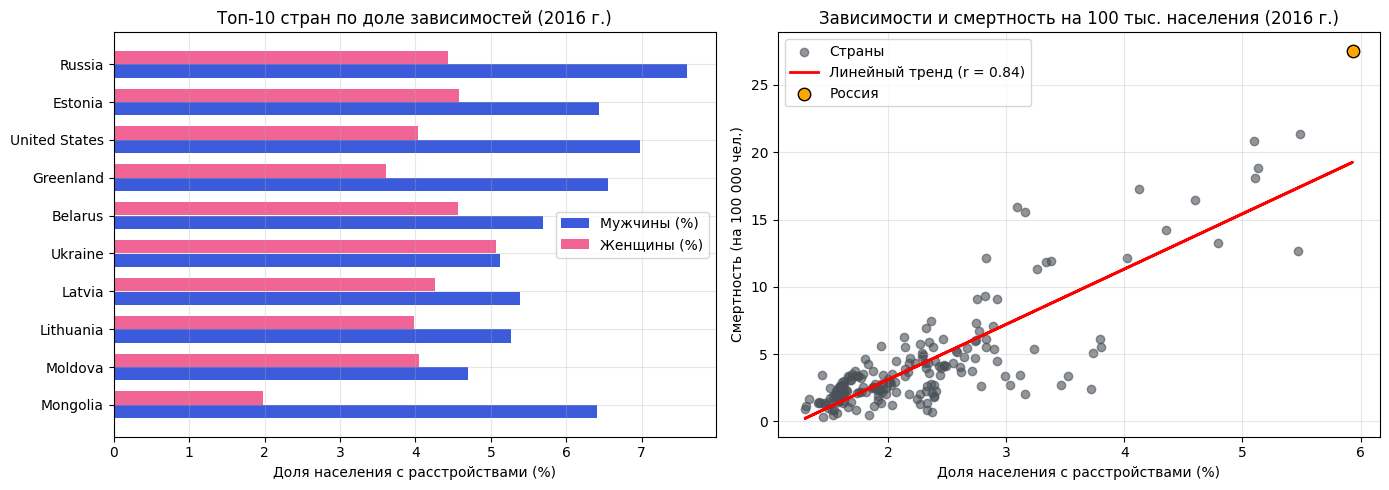

Средняя доля ментальных расстройств (2016 г.): 13.39%


In [4]:
last_alc_y = alcohol['year'].max()
alc_2016 = alcohol[alcohol['year'] == last_alc_y].copy()

top10 = alc_2016.sort_values('alcohol_drug_disorders_pct_all', ascending=False).head(10)
top10 = top10.sort_values('alcohol_drug_disorders_pct_all')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

y_pos = np.arange(len(top10))
ax1.barh(y_pos - 0.18, top10['alcohol_drug_disorders_pct_male'], height=0.35, label='Мужчины (%)', color='#3b5bdb')
ax1.barh(y_pos + 0.18, top10['alcohol_drug_disorders_pct_female'], height=0.35, label='Женщины (%)', color='#f06595')
ax1.set_yticks(y_pos)
ax1.set_yticklabels(top10['country'])
ax1.set_title(f'Топ-10 стран по доле зависимостей ({last_alc_y} г.)')
ax1.set_xlabel('Доля населения с расстройствами (%)')
ax1.legend()

x = alc_2016['alcohol_drug_disorders_pct_all']
y = alc_2016['alcohol_drug_deaths_per_100k']
corr = x.corr(y)

ax2.scatter(x, y, alpha=0.6, color='#495057', label='Страны')

# линия тренда
k, b = np.polyfit(x, y, 1)
ax2.plot(x, k * x + b, color='red', linewidth=2, label=f'Линейный тренд (r = {corr:.2f})')

rus = alc_2016[alc_2016['country'] == 'Russia']
ax2.scatter(rus['alcohol_drug_disorders_pct_all'], rus['alcohol_drug_deaths_per_100k'],
            color='orange', edgecolor='black', s=80, zorder=5, label='Россия')

ax2.set_title(f'Зависимости и смертность на 100 тыс. населения ({last_alc_y} г.)')
ax2.set_xlabel('Доля населения с расстройствами (%)')
ax2.set_ylabel('Смертность (на 100 000 чел.)')
ax2.legend()

plt.tight_layout()
plt.show()

print(f"Средняя доля ментальных расстройств ({last_alc_y} г.): {alc_2016['mental_disorders_pct_all'].mean():.2f}%")

## 5. Анализ опроса: цели, препятствия и удержание привычек

Данные опроса 1 000 человек (`desired_habits_survey.csv`) показывают, какие привычки люди хотят развивать, что им мешает и сколько дней они удерживают результат.

,count,median_days,retention_pct,share_pct
desired_habit,,,,
Спорт и физическая активность,270,52.0,23.3,27.0
Здоровое питание,198,61.5,21.2,19.8
Питьевой режим (вода),117,99.0,43.6,11.7
Здоровый сон,96,53.0,20.8,9.6
"Изучение нового (языки, навыки)",96,43.0,18.8,9.6
Медитация и ментальное здоровье,86,54.5,24.4,8.6
Чтение,78,53.5,25.6,7.8
Экономия денег,59,60.0,23.7,5.9


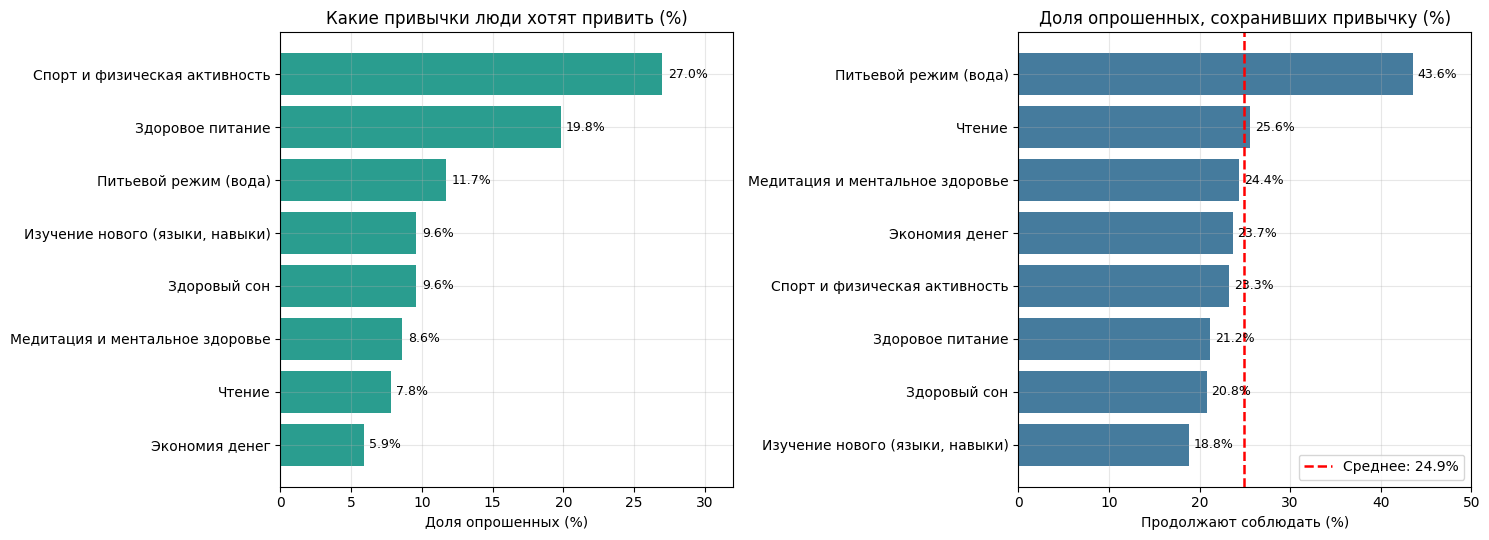

In [5]:
habits = survey.groupby('desired_habit').agg(
    count=('respondent_id', 'count'),
    median_days=('days_kept', 'median'),
    retention_pct=('still_keeping', lambda s: round(s.mean() * 100, 1))
).sort_values('count', ascending=True)
habits['share_pct'] = (habits['count'] / len(survey) * 100).round(1)

display(habits.sort_values('count', ascending=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

ax1.barh(habits.index, habits['share_pct'], color='#2a9d8f')
ax1.set_title('Какие привычки люди хотят привить (%)')
ax1.set_xlabel('Доля опрошенных (%)')
for i, v in enumerate(habits['share_pct']):
    ax1.text(v + 0.4, i, f'{v}%', va='center', fontsize=9)
ax1.set_xlim(0, 32)

habits_ret = habits.sort_values('retention_pct', ascending=True)
avg_ret = survey['still_keeping'].mean() * 100

ax2.barh(habits_ret.index, habits_ret['retention_pct'], color='#457b9d')
ax2.axvline(avg_ret, color='red', linestyle='--', linewidth=1.8, label=f'Среднее: {avg_ret:.1f}%')
ax2.set_title('Доля опрошенных, сохранивших привычку (%)')
ax2.set_xlabel('Продолжают соблюдать (%)')
for i, v in enumerate(habits_ret['retention_pct']):
    ax2.text(v + 0.5, i, f'{v}%', va='center', fontsize=9)
ax2.set_xlim(0, 50)
ax2.legend()

plt.tight_layout()
plt.show()

,count,median_days,retention_pct,share_pct
main_obstacle,,,,
Нет времени,271,59.0,26.2,27.1
Не хватает силы воли,236,50.5,20.3,23.6
Стресс,178,57.5,23.6,17.8
Старые привычки,158,64.0,27.2,15.8
Нереалистичные ожидания,85,56.0,22.4,8.5
Слишком строгие правила для себя,72,62.0,36.1,7.2


C:\Users\kryko\AppData\Local\Temp\ipykernel_13724\1552270296.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot(box_data, vert=False, labels=obs_order, showfliers=False)


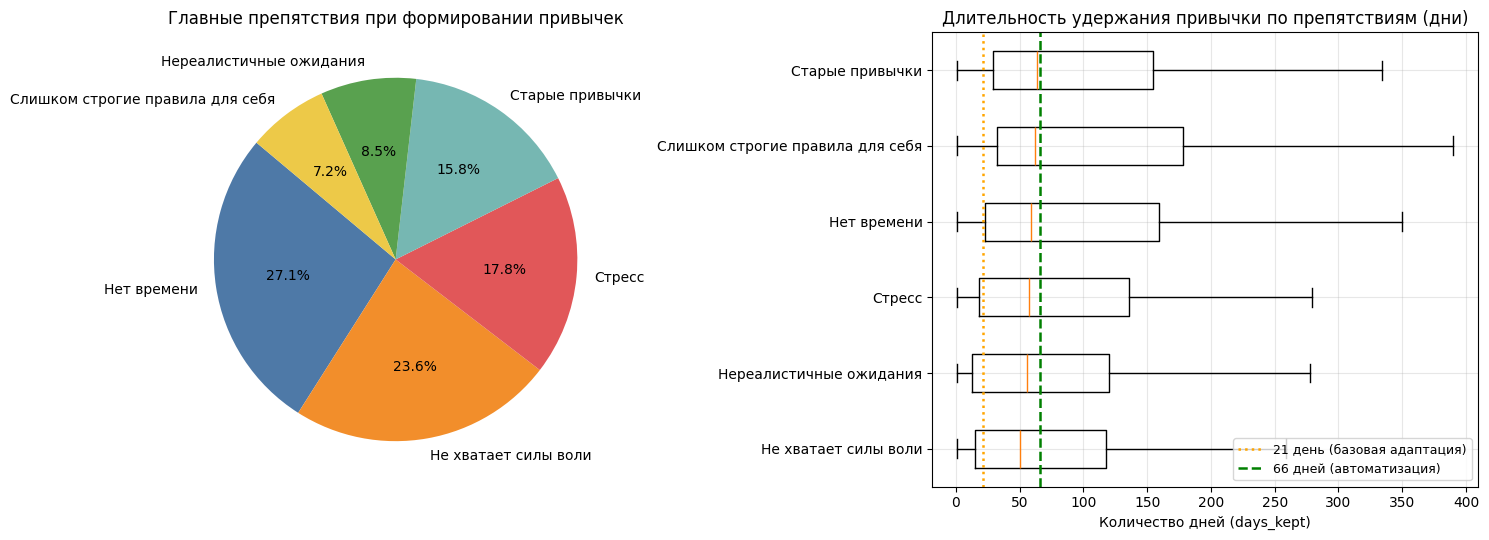

In [6]:
obstacles = survey.groupby('main_obstacle').agg(
    count=('respondent_id', 'count'),
    median_days=('days_kept', 'median'),
    retention_pct=('still_keeping', lambda s: round(s.mean() * 100, 1))
).sort_values('count', ascending=False)
obstacles['share_pct'] = (obstacles['count'] / len(survey) * 100).round(1)
display(obstacles)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

ax1.pie(
    obstacles['count'],
    labels=obstacles.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4e79a7', '#f28e2b', '#e15759', '#76b7b2', '#59a14f', '#edc948']
)
ax1.set_title('Главные препятствия при формировании привычек')

# распределение дней по препятствиям
obs_order = survey.groupby('main_obstacle')['days_kept'].median().sort_values().index
box_data = [survey[survey['main_obstacle'] == o]['days_kept'].values for o in obs_order]

ax2.boxplot(box_data, vert=False, labels=obs_order, showfliers=False)
ax2.axvline(21, color='orange', linestyle=':', linewidth=1.8, label='21 день (базовая адаптация)')
ax2.axvline(66, color='green', linestyle='--', linewidth=1.8, label='66 дней (автоматизация)')
ax2.set_title('Длительность удержания привычки по препятствиям (дни)')
ax2.set_xlabel('Количество дней (days_kept)')
ax2.legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()

## 6. Выводы по результатам анализа

1. **Актуальность режима «Получение полезных привычек»:**
   - За 40 лет (1975–2014 гг.) доля взрослого населения с ожирением в мире выросла почти в 3 раза — с **4,5% до 12,8%**, а в Европе и Северной Америке достигла **27,7%**.
   - По данным опроса, наиболее востребованными у людей являются именно привычки здорового образа жизни: **спорт (27,0%)**, **здоровое питание (19,8%)** и **питьевой режим (11,7%)** — суммарно **58,5%** всех запросов.
   - Уведомления от бота и отметка выполнения в заданное время помогают закреплять такие регулярные действия (например, питьевой режим уже сейчас имеет самый высокий процент удержания — **43,6%**).

2. **Актуальность режима «Отказ от вредных привычек»:**
   - В России доля курящего взрослого населения составляет **31,9%** (против **17,1%** в среднем по миру), а среднее число выкуриваемых сигарет выросло до **24,4 шт. в день**.
   - По доле населения с алкогольными и наркотическими расстройствами Россия занимает 1-е место в выборке (**5,93%** населения и **27,5 смертей на 100 тыс. чел.**), при этом наблюдается заметная положительная корреляция ($r = 0.68$) между уровнем зависимостей и смертностью.
   - Ежедневная вечерняя фиксация через кнопки «Да / Нет» в боте позволяет отслеживать дни воздержания и вовремя замечать срывы.

3. **Обоснование модулей «Статистика (серии)» и «История и отчёты»:**
   - Только **24,9%** опрошенных продолжают соблюдать начатую привычку, а медианный срок удержания составляет **57 дней** (ниже порога закрепления привычки в 66 дней).
   - Главные причины срывов — **нехватка времени (27,1%)**, **недостаток силы воли (23,6%)** и **стресс (17,8%)**. При нехватке силы воли медиана удержания падает до **50,5 дней**, а доля успеха — до **20,3%**.
   - Подсчёт непрерывных серий (streaks), процента выполнения и наглядные отчёты за неделю/месяц компенсируют дефицит силы воли за счёт визуализации прогресса и поддержания мотивации.